In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile, os

zip_path     = '/content/drive/MyDrive/Colab Notebooks/dataset/archive.zip'
extract_path = '/content/chest_xray'

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print('Extraction done!')

Extraction done!


In [3]:
!pip install mlflow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 109.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 124.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 92.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
import os, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from glob import glob

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, f1_score, accuracy_score
)

try:
    import mlflow, mlflow.keras
    MLFLOW_AVAILABLE = True
    print('MLflow loaded.')
except ImportError:
    MLFLOW_AVAILABLE = False
    print('MLflow not found.')

print('TensorFlow:', tf.__version__)
print('GPU:', bool(tf.config.list_physical_devices('GPU')))

MLflow loaded.
TensorFlow: 2.21.0
GPU: True


In [5]:
DATASET_ROOT = '/content/chest_xray/chest_xray'
CLASSES      = ['NORMAL', 'PNEUMONIA']
IMG_SIZE     = 224
BATCH_SIZE   = 32
EPOCHS_HEAD  = 10
EPOCHS_FINE  = 20
SEED         = 42
THRESHOLD    = 0.87
N_TTA        = 5

tf.random.set_seed(SEED)
np.random.seed(SEED)
print('Config ready.')

Config ready.


In [6]:
for split in ['train', 'val', 'test']:
    print(f'\n── {split.upper()} ──')
    for cls in CLASSES:
        path  = os.path.join(DATASET_ROOT, split, cls)
        count = len(os.listdir(path))
        print(f'  {cls}: {count} images')


── TRAIN ──
  NORMAL: 1341 images
  PNEUMONIA: 3875 images

── VAL ──
  NORMAL: 8 images
  PNEUMONIA: 8 images

── TEST ──
  NORMAL: 234 images
  PNEUMONIA: 390 images


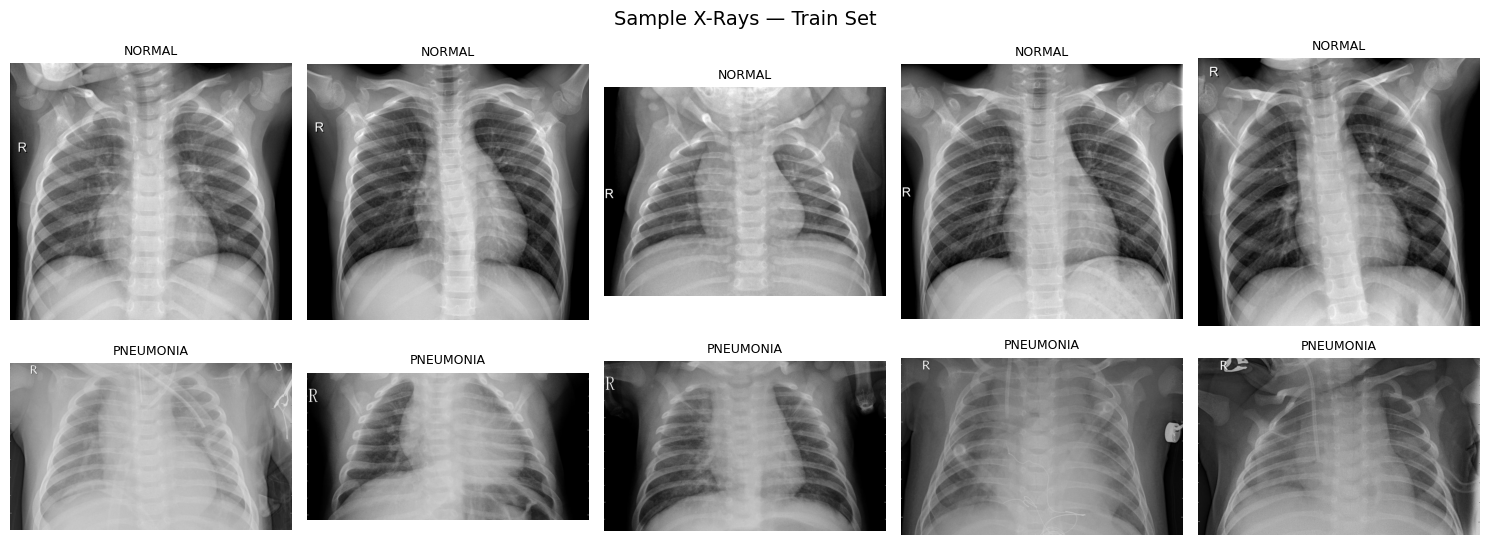

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Sample X-Rays — Train Set', fontsize=14)
for row, cls in enumerate(CLASSES):
    imgs = glob(os.path.join(DATASET_ROOT, 'train', cls, '*.jpeg'))
    for col, path in enumerate(random.sample(imgs, 5)):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(cls, fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

In [8]:
for cls in CLASSES:
    src = os.path.join(DATASET_ROOT, 'val',   cls)
    dst = os.path.join(DATASET_ROOT, 'train', cls)
    for f in os.listdir(src):
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))

print('Val merged into train.')
for cls in CLASSES:
    print(f'  {cls}: {len(os.listdir(os.path.join(DATASET_ROOT, "train", cls)))} images')

Val merged into train.
  NORMAL: 1349 images
  PNEUMONIA: 3883 images


In [9]:
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

normal_train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.10,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest',
).flow_from_directory(
    os.path.join(DATASET_ROOT, 'train'), classes=['NORMAL'],
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE//2,
    class_mode='binary', seed=SEED)

pneumonia_train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest',
).flow_from_directory(
    os.path.join(DATASET_ROOT, 'train'), classes=['PNEUMONIA'],
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE//2,
    class_mode='binary', seed=SEED)

test_gen = eval_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False)

def balanced_generator(gen_a, gen_b):
    """gen_a = NORMAL images (label=0), gen_b = PNEUMONIA images (label=1)"""
    w_normal, w_pneu = 2.0, 1.0
    while True:
        x0, _ = next(gen_a)
        x1, _ = next(gen_b)
        x  = np.concatenate([x0, x1])
        # FIX: hardcode correct labels — flow_from_directory with single class returns 0 for both
        y0 = np.zeros(len(x0), dtype=np.float32)   # NORMAL = 0
        y1 = np.ones(len(x1),  dtype=np.float32)   # PNEUMONIA = 1
        y  = np.concatenate([y0, y1])
        w  = np.where(y == 0, w_normal, w_pneu)
        yield x, y, w

train_gen = balanced_generator(normal_train_gen, pneumonia_train_gen)
steps_per_epoch = (len(normal_train_gen) + len(pneumonia_train_gen)) // 2
print(f'Steps per epoch: {steps_per_epoch}')

Found 1349 images belonging to 1 classes.
Found 3883 images belonging to 1 classes.
Found 624 images belonging to 2 classes.
Steps per epoch: 164


In [10]:
def build_model(trainable_base=False):
    base = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = trainable_base

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization(name='bn')(x)
    x = layers.Dense(512, activation='relu', name='dense_512')(x)
    x = layers.Dropout(0.5, name='dropout_05')(x)
    x = layers.Dense(128, activation='relu', name='dense_128')(x)
    x = layers.Dropout(0.3, name='dropout_03')(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    return keras.Model(inputs, outputs, name='pneumonia_densenet121')

model      = build_model(trainable_base=False)
base_model = model.get_layer('densenet121')
model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "pneumonia_densenet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn (BatchNormalization)         │ (None, 1024)           │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_05 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_03 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,632,193 (29.11 MB)

 Trainable params: 592,641 (2.26 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

In [11]:
def focal_loss(gamma=2.0, alpha=0.25):
    """alpha = weight for PNEUMONIA (positive class). NORMAL gets (1-alpha)."""
    def loss_fn(y_true, y_pred):
        y_pred  = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        pt      = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1),
                           tf.ones_like(y_true) * alpha,
                           tf.ones_like(y_true) * (1 - alpha))
        fl = -alpha_t * tf.pow(1 - pt, gamma) * tf.math.log(pt)
        return tf.reduce_mean(fl)
    return loss_fn

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),
    ]
)

callbacks_p1 = [
    keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=5,
        restore_best_weights=True, mode='max', verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_auc', factor=0.5, patience=3,
        min_lr=1e-7, mode='max', verbose=1),
    keras.callbacks.ModelCheckpoint(
        'best_phase1.keras', monitor='val_auc',
        save_best_only=True, mode='max', verbose=1),
]

history1 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS_HEAD,
    validation_data=test_gen,
    callbacks=callbacks_p1,
    verbose=1,
)

Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8846 - auc: 0.9552 - loss: 0.0545 - precision: 0.9301 - recall: 0.8301
Epoch 1: val_auc improved from None to 0.95353, saving model to best_phase1.keras

Epoch 1: finished saving model to best_phase1.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 245s 1s/step - accuracy: 0.9213 - auc: 0.9787 - loss: 0.0395 - precision: 0.9574 - recall: 0.8822 - val_accuracy: 0.8638 - val_auc: 0.9535 - val_loss: 0.0582 - val_precision: 0.8474 - val_recall: 0.9538 - learning_rate: 0.0010
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9402 - auc: 0.9877 - loss: 0.0266 - precision: 0.9737 - recall: 0.9059
Epoch 2: val_auc did not improve from 0.95353
164/164 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.9433 - auc: 0.9891 - loss: 0.0241 - precision: 0.9727 - recall: 0.9126 - val_accuracy: 0.8718 - val_auc: 0.9482 - val_loss: 0.0496 - val_precision: 0.8605 - val_recall: 0.9487 - learning_rate: 0.0010
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━

In [12]:
%%javascript
function ClickConnect(){
    console.log("Keeping alive...");
    document.querySelector("colab-toolbar-button#connect").click()
}
setInterval(ClickConnect, 60000)

<IPython.core.display.Javascript object>

In [13]:

import os

for f in ['best_phase1.h5', 'best_phase2.h5']:
    if os.path.exists(f):
        os.remove(f)
        print(f'Removed: {f}')

# Recreate generator after Phase 1
train_gen = balanced_generator(normal_train_gen, pneumonia_train_gen)
test_gen.reset()

base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

trainable = sum(1 for l in base_model.layers if l.trainable)
print(f'Trainable base layers: {trainable} / {len(base_model.layers)}')

total_steps = steps_per_epoch * EPOCHS_FINE
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps,
    alpha=1e-6,
)

model.compile(
    optimizer=keras.optimizers.Adam(lr_schedule),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),
    ]
)

callbacks_p2 = [
    keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=7,
        restore_best_weights=True, mode='max', verbose=1),
    keras.callbacks.ModelCheckpoint(
        'best_phase2.keras', monitor='val_auc',
        save_best_only=True, mode='max', verbose=1),
]

history2 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS_FINE,
    validation_data=test_gen,
    callbacks=callbacks_p2,
    verbose=1,
)

Trainable base layers: 50 / 427
Epoch 1/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9721 - auc: 0.9968 - loss: 0.0116 - precision: 0.9867 - recall: 0.9573
Epoch 1: val_auc improved from None to 0.96075, saving model to best_phase2.keras

Epoch 1: finished saving model to best_phase2.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 279s 1s/step - accuracy: 0.9730 - auc: 0.9966 - loss: 0.0118 - precision: 0.9882 - recall: 0.9576 - val_accuracy: 0.8878 - val_auc: 0.9608 - val_loss: 0.0991 - val_precision: 0.8704 - val_recall: 0.9641
Epoch 2/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 913ms/step - accuracy: 0.9755 - auc: 0.9975 - loss: 0.0109 - precision: 0.9906 - recall: 0.9602
Epoch 2: val_auc improved from 0.96075 to 0.97308, saving model to best_phase2.keras

Epoch 2: finished saving model to best_phase2.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 161s 984ms/step - accuracy: 0.9759 - auc: 0.9978 - loss: 0.0101 - precision: 0.9906 - recall: 0.9611 - val_accuracy: 0.8926 - val_auc: 0.9731 - val_loss: 0.061

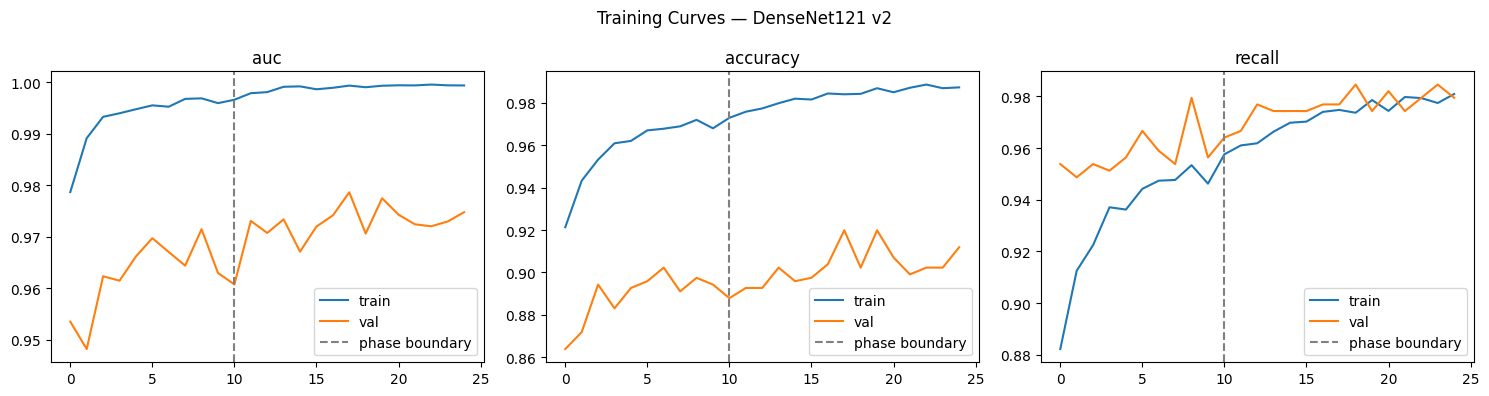

In [14]:
def plot_history(h1, h2, metric, ax):
    values     = h1.history[metric]          + h2.history[metric]
    val_values = h1.history[f'val_{metric}'] + h2.history[f'val_{metric}']
    ax.plot(values,     label='train')
    ax.plot(val_values, label='val')
    ax.axvline(len(h1.history[metric]), color='gray', linestyle='--', label='phase boundary')
    ax.set_title(metric)
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_history(history1, history2, 'auc',      axes[0])
plot_history(history1, history2, 'accuracy', axes[1])
plot_history(history1, history2, 'recall',   axes[2])
plt.suptitle('Training Curves — DenseNet121 v2')
plt.tight_layout()
plt.show()

In [15]:
tta_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=5,
    zoom_range=0.05,
)

tta_preds = []
for i in range(N_TTA):
    tta_gen = tta_datagen.flow_from_directory(
        os.path.join(DATASET_ROOT, 'test'),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='binary',
        shuffle=False,
        seed=i * 7,
    )
    tta_preds.append(model.predict(tta_gen, verbose=0).flatten())
    print(f'TTA pass {i+1}/{N_TTA} done')

y_pred_prob = np.mean(tta_preds, axis=0)
test_gen.reset()
y_true = test_gen.classes
y_pred = (y_pred_prob > THRESHOLD).astype(int)

print(f'\nTTA passes: {N_TTA}  |  Threshold: {THRESHOLD}')
print('\n── Classification Report ──')
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))
print(f'AUC-ROC: {roc_auc_score(y_true, y_pred_prob):.4f}')

Found 624 images belonging to 2 classes.
TTA pass 1/5 done
Found 624 images belonging to 2 classes.
TTA pass 2/5 done
Found 624 images belonging to 2 classes.
TTA pass 3/5 done
Found 624 images belonging to 2 classes.
TTA pass 4/5 done
Found 624 images belonging to 2 classes.
TTA pass 5/5 done

TTA passes: 5  |  Threshold: 0.87

── Classification Report ──
              precision    recall  f1-score   support

      NORMAL       0.92      0.94      0.93       234
   PNEUMONIA       0.96      0.95      0.96       390

    accuracy                           0.95       624
   macro avg       0.94      0.94      0.94       624
weighted avg       0.95      0.95      0.95       624

AUC-ROC: 0.9842


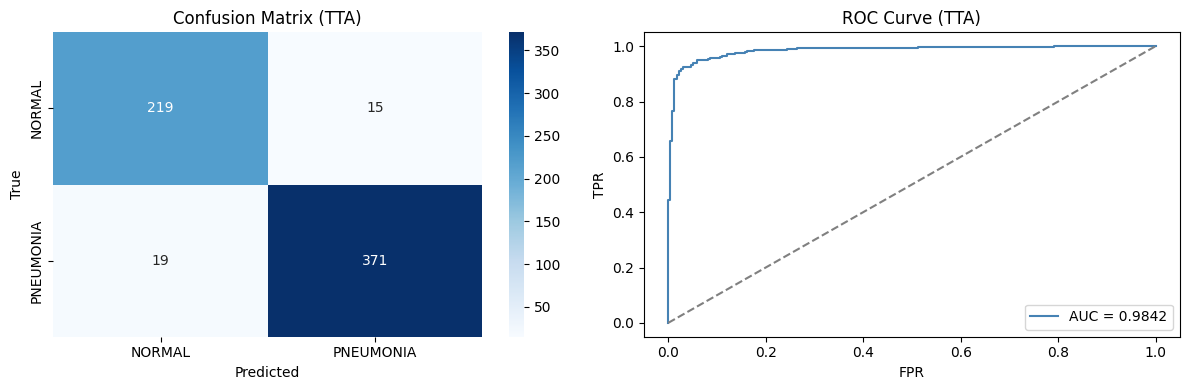

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'], ax=axes[0])
axes[0].set_title('Confusion Matrix (TTA)')
axes[0].set_ylabel('True')
axes[0].set_xlabel('Predicted')

fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
auc_score   = roc_auc_score(y_true, y_pred_prob)
axes[1].plot(fpr, tpr, label=f'AUC = {auc_score:.4f}', color='steelblue')
axes[1].plot([0,1],[0,1],'--', color='gray')
axes[1].set_title('ROC Curve (TTA)')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].legend()
plt.tight_layout()
plt.show()

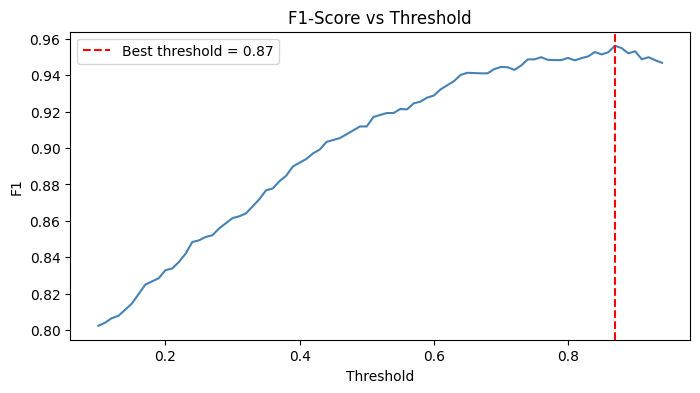

Best threshold: 0.87  |  F1: 0.9562
              precision    recall  f1-score   support

      NORMAL       0.92      0.94      0.93       234
   PNEUMONIA       0.96      0.95      0.96       390

    accuracy                           0.95       624
   macro avg       0.94      0.94      0.94       624
weighted avg       0.95      0.95      0.95       624



In [17]:
thresholds  = np.arange(0.1, 0.95, 0.01)
f1_scores   = [f1_score(y_true, (y_pred_prob > t).astype(int)) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color='steelblue')
plt.axvline(best_thresh, color='red', linestyle='--',
            label=f'Best threshold = {best_thresh:.2f}')
plt.title('F1-Score vs Threshold')
plt.xlabel('Threshold')
plt.ylabel('F1')
plt.legend()
plt.show()

print(f'Best threshold: {best_thresh:.2f}  |  F1: {max(f1_scores):.4f}')
y_pred_best = (y_pred_prob > best_thresh).astype(int)
print(classification_report(y_true, y_pred_best, target_names=['NORMAL', 'PNEUMONIA']))

In [18]:
if MLFLOW_AVAILABLE:
    cm = confusion_matrix(y_true, y_pred_best)
    mlflow.set_experiment('pneumonia-xray-classification')
    with mlflow.start_run(run_name='densenet121-focal-cosine-tta'):
        mlflow.log_params({
            'backbone':        'DenseNet121',
            'img_size':        IMG_SIZE,
            'batch_size':      BATCH_SIZE,
            'epochs_head':     EPOCHS_HEAD,
            'epochs_fine':     EPOCHS_FINE,
            'loss':            'focal_loss(gamma=2, alpha=0.25)',
            'lr_phase1':       '1e-3 Adam',
            'lr_phase2':       'CosineDecay(1e-4 to 1e-6)',
            'tta_passes':      N_TTA,
            'threshold':       best_thresh,
            'unfreeze_layers': 50,
        })
        mlflow.log_metrics({
            'test_accuracy':    round(accuracy_score(y_true, y_pred_best), 4),
            'test_auc_roc':     round(roc_auc_score(y_true, y_pred_prob), 4),
            'normal_recall':    round(cm[0,0] / cm[0].sum(), 4),
            'pneumonia_recall': round(cm[1,1] / cm[1].sum(), 4),
            'f1_weighted':      round(f1_score(y_true, y_pred_best, average='weighted'), 4),
        })
        mlflow.keras.log_model(model, artifact_path='densenet121_model')
        print('MLflow run logged!')
else:
    print('MLflow not available.')

2026/10/16 11:36:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 11:36:37 INFO mlflow.store.db.utils: Updating database tables
2026/10/16 11:36:39 INFO mlflow.tracking.fluent: Experiment with name 'pneumonia-xray-classification' does not exist. Creating a new experiment.
2026/10/16 11:36:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/16 11:36:39 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/10/16 11:36:56 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmpnw5jc2c1/model, flavor: keras). Fall back to return ['keras==3.13.2']. Set logging level to DEBUG to see the full traceback. 


MLflow run logged!


In [19]:
save_path = '/content/drive/MyDrive/Colab Notebooks/pneumonia_densenet121_v2.keras'
model.save(save_path)
print(f'Model saved → {save_path}')

Model saved → /content/drive/MyDrive/Colab Notebooks/pneumonia_densenet121_v2.keras
